# ¿Es posible reconstruir la imagen de manera única?

Continuaremos trabajando con la matriz $X_{\text{fantoma}}$ y el vector $x_{\text{fantoma}}$ del Ejercicio 1, junto con la función `matriz_proyeccion` implementada anteriormente. El objetivo es investigar si las mediciones $b = Ax$ contienen información suficiente para recuperar una imagen de $8 \times 8$ de manera única. Para ello, analizaremos el rango y el espacio nulo de distintas matrices de proyección.





In [22]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Fantoma del ejercicio 1 (matriz y vector)
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)
x_v_fantoma = X_fantoma.reshape(-1)


# Funciones de los ejercicios 2 y 3 (copiadas para que el notebook sea autocontenido)
def mascara_rayo(n, direccion, s):
    M = np.zeros((n, n))
    i, j = np.ogrid[:n, :n]
    condicion = (i * direccion[0] + j * direccion[1] == s)   # píxeles cuyo centro cumple α·i + β·j = s
    M[condicion] = 1
    return M


def matriz_proyeccion(n, direcciones):
    i, j = np.indices((n, n))
    filas = []    # filas de A, una por rayo
    rayos = []    # par ((α, β), s) de cada fila
    for (alfa, beta) in direcciones:
        S = alfa * i + beta * j               # a qué rayo pertenece cada píxel
        for s in np.unique(S):                # cada valor distinto de s es un rayo
            M = mascara_rayo(n, (alfa, beta), s)
            filas.append(M.reshape(-1))       # máscara vectorizada -> fila de A
            rayos.append(((alfa, beta), int(s)))
    A = np.array(filas, dtype=float)
    return A, rayos

# Carpeta para guardar las figuras
os.makedirs('figuras', exist_ok=True)

#### a) Considerar una matriz de proyección $A \in \mathbb{R}^{m \times 64}$. Utilizando el teorema de rango y nulidad, determinar qué condición debe cumplir $\text{rango}(A)$ para que la imagen pueda reconstruirse de manera única. Explicar qué ocurre si existe un vector no nulo $v$ tal que $Av = 0$ y relacionar $\text{rango}(A)$ con $\dim(\text{Nul}(A))$.




La matriz $A$ tiene 64 columnas, una por píxel. Por el teorema del rango y nulidad 

$$\text{rango}(A) + \dim(\text{Nul}(A)) = 64$$

Para que la imagen se pueda reconstruir de forma única, necesitamos que el sistema $Ax = b$ tenga una sola solución. Si $x$ es una solución, el conjunto de todas las soluciones es $x + \text{Nul}(A)$, es decir, una solución particular más las soluciones del sistema homogéneo $Av = 0$. Por ende, la solución es única solo si el espacio nulo solo tiene la solucion trivial

$$\text{solución única} \iff \text{Nul}(A) = \{0\} \iff \dim(\text{Nul}(A)) = 0 \iff \text{rango}(A) = 64$$

Es decir, las 64 columnas de $A$  tienen que ser linealmente independientes. Como $A$ en general no es cuadrada, no se puede usar el determinante ni la inversa, lo que importa es el rango. Esto requiere $m \ge 64$, pero tener 64 filas o más no alcanza, porque algunas pueden ser redundantes (linealmente dependiente).

Si existe $v \neq 0$ con $Av = 0$, entonces $\text{Nul}(A) \neq \{0\}$ y, por lo anterior, $\text{rango}(A) < 64$. En ese caso, por linealidad, para cualquier $\gamma$

$$A(x + \gamma v) = Ax + \gamma\,Av = b + 0 = b$$

Es decir, hay infinitas imágenes distintas que producen exactamente las mismas mediciones, y a partir de $b$ no hay forma de saber cuál es la real. Además, como $Av = 0$ significa que $a_r^T v = 0$ para cada fila, el patrón $v$ suma cero a lo largo de todos los rayos, es información de la imagen que el escáner no puede ver.

#### b) Construir las matrices $A_2$, $A_4$ y $A_7$ utilizando $D_2 = \{(1, 0), (0, 1)\}$, $D_4 = D_2 \cup \{(1, 1), (1, -1)\}$ y $D_7 = D_4 \cup \{(2, 1), (1, 2), (3, 1)\}$. Para cada matriz, informar sus dimensiones, su rango, la dimensión de su espacio nulo y si permite determinar una imagen de manera única. Comparar la cantidad de filas con el rango e identificar la presencia de mediciones redundantes.

In [23]:
#Conjunto de direcciones de los rayos
D2=[(1, 0), (0, 1)]
D4=D2+[(1,1),(1,-1)]
D7=D4+[(2,1),(1,2),(3,1)]

#Matrices de proyeccion
A2, rayos2 = matriz_proyeccion(8, D2)
A4, rayos4 = matriz_proyeccion(8, D4)
A7, rayos7 = matriz_proyeccion(8, D7)

print(f"{'Matriz':<8}{'Filas':>7}{'Columnas':>10}{'Rango':>7}{'dim Nul':>9}{'Redundantes':>13}{'Única':>8}")
for nombre, A in [("A2", A2), ("A4", A4), ("A7", A7)]:
    filas, cols = A.shape
    rango = np.linalg.matrix_rank(A)
    nulidad = cols - rango
    redundantes = filas - rango
    unica = "Sí" if rango == cols else "No"
    print(f"{nombre:<8}{filas:>7}{cols:>10}{rango:>7}{nulidad:>9}{redundantes:>13}{unica:>8}")

Matriz    Filas  Columnas  Rango  dim Nul  Redundantes   Única
A2           16        64     15       49            1      No
A4           46        64     39       25            7      No
A7          119        64     64        0           55      Sí


Por lo visto en el inciso a (teorema de rango y nulidad), solo la matriz $A_7$ permite reconstruir la imagen de manera única, porque solo ella cuenta con rango 64, es decir, su espacio nulo está formado únicamente por el vector cero (el sistema homogéneo solo tiene la solución trivial). $A_2$ y $A_4$ nunca podrían llegar a rango 64, porque el rango no puede ser mayor que la cantidad de filas. Con 16 y 46 filas, su rango es como máximo 16 y 46, incluso si todas sus filas fueran linealmente independientes.

Al agregar direcciones, el rango aumenta y el espacio nulo se achica ($\dim(\text{Nul})$ pasa de 49 a 25 y luego a 0). Cada nueva dirección agrega información de la imagen que las anteriores mediciones no podían ver. Es decir, a medida que agrego direcciones van quedando cada vez menos patrones invisibles para el escáner, por lo que logra capturar cada vez mejor la información de la imagen.

En las tres matrices hay mediciones redundantes, es decir, que no aportan información nueva( 1 en $A_2$, 7 en $A_4$ y 55 en $A_7$). Esto ocurre porque hay filas que son combinaciones lineales de las otras. Esto a su vez demuestra que no alcanza con tener más filas, lo que importa es el rango, es decir, la cantidad de filas linealmente independientes. Por ejemplo, $A_7$ tiene 119 filas, pero solo 64 aportan información nueva.

#### c) Para $A_4$, utilizar una descomposición SVD para encontrar un vector no nulo $v \in \mathbb{R}^{64}$ que pertenezca aproximadamente a su espacio nulo y verificar que $\|A_4 v\| \approx 0$. Calcular $b_4 = A_4\,x_{\text{fantoma}}$ y construir $x_{\text{alt}} = x_{\text{fantoma}} + \gamma v$, con $\gamma \neq 0$. Visualizar y verificar que producen aproximadamente las mismas mediciones e interpretar qué información de la imagen resulta invisible para $A_4$.

In [ ]:
# SVD de A4: A4 = U Σ Vᵀ  (s contiene los valores singulares de mayor a menor)
U, s, Vt = np.linalg.svd(A4)
rango4 = np.linalg.matrix_rank(A4)
print("Valores singulares 37 a 46:", [f"{x:.1e}" for x in s[36:]])

# Base del espacio nulo: filas de Vt desde la posición del rango en adelante
base_nula = Vt[rango4:]
print(f"Vectores en la base del espacio nulo: {base_nula.shape[0]}")

# Elegimos un vector de esa base
v = Vt[-1]   # última fila de Vt
print(f"||v|| = {np.linalg.norm(v):.4f}")          # no es nulo
print(f"||A4 v|| = {np.linalg.norm(A4 @ v):.2e}")  # está en Nul(A4)

# Mediciones del fantoma y de la imagen alternativa
b4 = A4 @ x_v_fantoma
gamma = 1
x_alt = x_v_fantoma + gamma * v
b_alt = A4 @ x_alt

print(f"||b_alt - b4|| = {np.linalg.norm(b_alt - b4):.2e}")
print(f"||x_alt - x_fantoma|| = {np.linalg.norm(x_alt - x_v_fantoma):.4f}")
print(f"Mínimo de x_alt: {x_alt.min():.3f}")


Valores singulares 37 a 46: ['1.0e+00', '1.0e+00', '9.1e-01', '2.4e-15', '6.8e-16', '6.6e-16', '6.5e-16', '6.0e-16', '4.5e-16', '4.5e-16']
Vectores en la base del espacio nulo: 25
||v|| = 1.0000
||A4 v|| = 1.04e-15
||b_alt - b4|| = 1.48e-15
||x_alt - x_fantoma|| = 1.0000
Mínimo de x_alt: -0.230


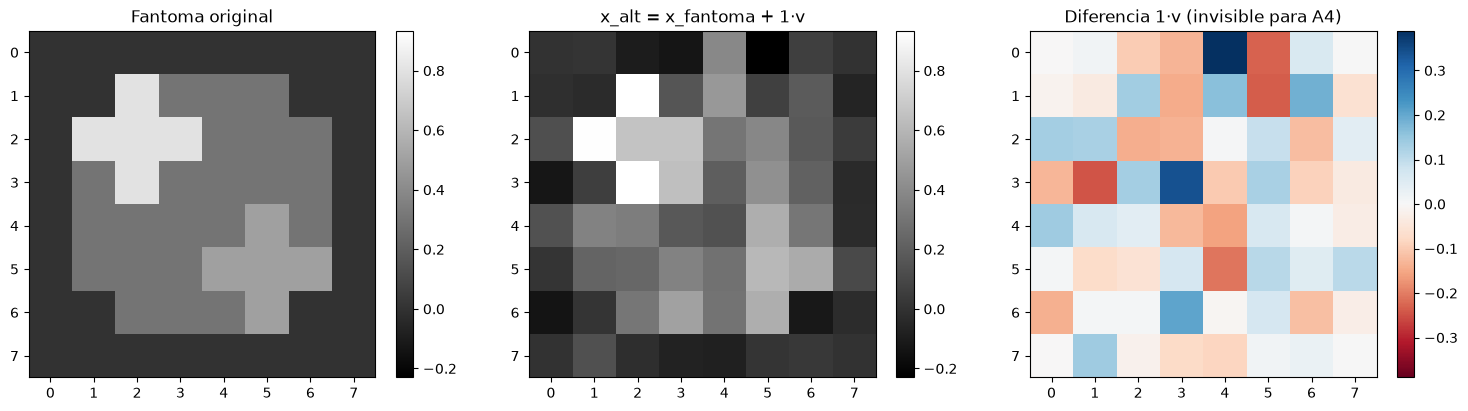

In [25]:
#Graficos
X_alt = x_alt.reshape(8, 8)
V = v.reshape(8, 8)

vmin = min(X_fantoma.min(), X_alt.min())   # misma escala para fantoma y alternativa
vmax = max(X_fantoma.max(), X_alt.max())
lim = np.abs(gamma * V).max()              # escala simétrica para la diferencia

fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')

im0 = axes[0].imshow(X_fantoma, cmap='gray', vmin=vmin, vmax=vmax)
axes[0].set_title('Fantoma original')
fig.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(X_alt, cmap='gray', vmin=vmin, vmax=vmax)
axes[1].set_title(f'x_alt = x_fantoma + {gamma}·v')
fig.colorbar(im1, ax=axes[1])

im2 = axes[2].imshow(gamma * V, cmap='RdBu', vmin=-lim, vmax=lim)
axes[2].set_title(f'Diferencia {gamma}·v (invisible para A4)')
fig.colorbar(im2, ax=axes[2])

for ax in axes:
    ax.set_xticks(range(8))
    ax.set_yticks(range(8))

plt.savefig('figuras/ejercicio_04c.png', dpi=150)
plt.show()

**Paso 1: descomposición de $A_4$ en valores singulares (SVD)**

Toda matriz, aunque no sea cuadrada, admite una descomposición en valores singulares de la forma

$$A_4 = U\,\Sigma\,V^T$$

donde $U \in \mathbb{R}^{46\times46}$ y $V \in \mathbb{R}^{64\times64}$ son matrices ortogonales y $\Sigma \in \mathbb{R}^{46\times64}$ tiene los valores singulares $\sigma_1 \ge \sigma_2 \ge \dots \ge 0$ en la diagonal y ceros en el resto.

La SVD de una matriz $A \in \mathbb{R}^{m\times N}$ (en este caso $m = 46$ y $N = 64$) se obtiene de la siguiente manera:

1) Se calcula $A^TA$, que es una matriz simétrica de $N\times N$.
2) Se encuentran los autovalores de $A^TA$, resolviendo $\det(A^TA - \lambda I) = 0$, y se ordenan de mayor a menor.
3) Se calculan los valores singulares como $\sigma_i = \sqrt{\lambda_i}$. La cantidad de $\sigma_i > 0$ es el rango $r$.
4) Se encuentran los autovectores de $A^TA$, resolviendo $(A^TA - \lambda_i I)v = 0$, y se normalizan para que $\|v_i\| = 1$. Si un autovalor se repite, se usa Gram–Schmidt para que sus autovectores queden ortogonales entre sí. Los $v_i$ son las columnas de $V$, en el mismo orden que los $\sigma_i$.
5) Se calculan los vectores $u_i$ para los $\sigma_i > 0$ como $$u_i = \frac{1}{\sigma_i}\,A\,v_i, \qquad i = 1,\dots,r$$ que resultan automáticamente de norma 1 y ortogonales entre sí.
6) Si $r < m$, se completa $U$ con $m - r$ vectores ortonormales y perpendiculares a los $u_i$ ya obtenidos (con Gram–Schmidt o como base de $\text{Nul}(A^T)$).
7) Se arma $\Sigma$, una matriz de $m\times N$ con $\sigma_1, \sigma_2, \dots$ en la diagonal y ceros en el resto.

En la práctica, `np.linalg.svd(A4)` no realiza exactamente estos pasos (usa algoritmos numéricos más estables que no calculan $A^TA$), pero el resultado es la misma descomposición. La función devuelve $U$, un vector con los valores singulares ordenados de mayor a menor y $V^T$, por lo que los vectores singulares derechos $v_i$ son las filas de `Vt`.

De la descomposición se deduce que multiplicando $A_4 = U\Sigma V^T$ a derecha por $V$ (y usando que $V^TV = I$), se obtiene, columna a columna,

$$A_4\,v_i = \sigma_i\,u_i$$

Es decir, cada $v_i$ es enviado por $A_4$ a la dirección $u_i$, multiplicado por $\sigma_i$. En particular, si $\sigma_i = 0$, entonces $A_4 v_i = 0$.


**Paso 2: base del espacio nulo**

Como la consigna pide encontrar un vector no nulo que pertenezca al espacio nulo de $A_4$, primero es necesario encontrar una base de ese espacio.

`np.linalg.svd` devuelve los valores singulares de mayor a menor, y las filas de `Vt` vienen en ese mismo orden. Por eso sabemos que para $A_4$, con rango 39 y $\dim(\text{Nul}(A_4)) = 25$:

- las filas 0 a 38 tienen un valor singular asociado mayor que 0;
- las filas 39 a 45 tienen un valor singular asociado prácticamente nulo (no es exacto por el redondeo de punto flotante que utiliza la libreria pra realizar cuentas matematicas);
- las filas 46 a 63 no tienen ningún valor singular asociado, porque $A_4$ tiene solo 46 filas y por eso solo hay 46 valores singulares. Las columnas correspondientes de $\Sigma$ son nulas.

Por la relación $A_4 v_i = \sigma_i u_i$, los vectores con $\sigma_i = 0$ (o sin valor singular asociado) cumplen $A_4 v_i = 0$, es decir, pertenecen al espacio nulo. Como los valores singulares están ordenados, todos estos vectores quedan al final de `Vt`, a partir de la posición del rango: `Vt[rango4:]`. Son $64 - 39 = 25$ vectores ortonormales (por lo tanto linealmente independientes), y como $\dim(\text{Nul}(A_4)) = 25$, forman una base del espacio nulo.

De esta base se eligió como $v$ la última fila de `Vt`, pero podríamos utilizar cualquier vector de esa base.


**Paso 3: verificación de que $v$ no es nulo y está en el espacio nulo**

Se calculó la norma de $v$ para verificar que no sea el vector nulo. El resultado es 1, porque las filas de `Vt` son ortonormales.

Se calculó $\|A_4 v\| \approx 10^{-15}$. Si $v$ está en el espacio nulo, todas las mediciones de esa imagen son cero, así que la norma tiene que ser $\approx 0$. 

**Paso 4: construcción de una imagen alternativa**

Primero se calcularon las mediciones del fantoma, $b_4 = A_4\,x_{\text{fantoma}}$, que simulan lo que mediría el escáner con las direcciones de $D_4$. Esto devuelve un vector de 46 componentes, una por cada rayo.

Luego se construyó una imagen alternativa sumándole al fantoma el vector $v$ encontrado en el paso anterior:

$$x_{\text{alt}} = x_{\text{fantoma}} + \gamma\,v$$


**Paso 5: verificación de que producen las mismas mediciones**

Por la linealidad de la transformación, y usando que $A_4 v = 0$

$$A_4\,x_{\text{alt}} = A_4\,x_{\text{fantoma}} + \gamma\,A_4 v = b_4 + \gamma\cdot 0 = b_4$$

Numéricamente se obtuvo $\|A_4 x_{\text{alt}} - b_4\| \approx 10^{-15}$, mientras que $\|x_{\text{alt}} - x_{\text{fantoma}}\| = |\gamma|\,\|v\| = 1$. Es decir, son dos imágenes claramente distintas que producen las mismas mediciones.


**Paso 6: visualización e información invisible para $A_4$**

En la figura se muestran tres imágenes:

- el fantoma original;
- la imagen alternativa $x_{\text{alt}}$, con la misma escala de color que el fantoma, para que un mismo tono represente el mismo valor en las dos;
- la diferencia $\gamma v$, usando rojo para valores negativos y azul para positivos.

A simple vista, el fantoma y $x_{\text{alt}}$ son imágenes claramente distintas. Sin embargo, como se verificó en el paso 5, producen las mismas 46 mediciones.

La información invisible para $A_4$ es la componente $\gamma v$. Como $A_4 v = 0$, cada fila de $A_4$ cumple $a_r^T v = 0$, el patrón $v$ suma cero a lo largo de todos los rayos de $A_4$, es decir, a lo largo de cada fila, cada columna y cada diagonal de la imagen. En la figura de la diferencia se ve que $v$ es un patrón oscilante, con valores positivos y negativos que se compensan dentro de cada rayo.

Como el escáner solo mide sumas a lo largo de los rayos, este patrón puede agregarse a cualquier imagen sin modificar ninguna medición. Cada rayo gana en algunos píxeles lo mismo que pierde en otros. Lo mismo ocurre con cualquier combinación de los 25 vectores de la base del espacio nulo, es decir, con cualquier imagen de la forma

$$x_{\text{fantoma}} + \gamma_1 v_{39} + \gamma_2 v_{40} + \dots + \gamma_{25} v_{63}$$

Por lo tanto, hay infinitas imágenes compatibles con las mismas mediciones $b_4$, y a partir de ellas es imposible saber cuál es la imagen real. Por eso, con $A_4$ (rango $39 < 64$), la imagen no puede reconstruirse de manera única, como se dedujo en el inciso a. Para eliminar las diferencias entre la reconstruccion de imagenes, es necesario agregar direcciones de rayos que puedan ver estos patrones, como ocurre con $A_7$, que tiene rango completo y espacio nulo trivial.

Además, $x_{\text{alt}}$ tiene valores negativos, que si bien no tienen sentido porque no existen atenuaciones negativas. Es una solución matematica válida para el sistema $A_4 x = b_4$.

Llevandolo a la vida real este ejercicio intenta explicar que si no cuenta con la suficiente cantidad de direcciones, que logren visualizar todos los patrones de la imagen el escaner puede devolver  mediciones que son compatibles con infinitas imágenes y no se puede saber cuál es la real. Al agregar direcciones de rayos, el escáner logra detectar cada vez más de estos patrones,hasta que los puntos ciegos desaparecen y la imagen queda determinada de forma única.
